# SHAP - Explainable AI untuk RoBERTa (Teks Manusia vs Generative AI)
**Skripsi:** Klasifikasi Teks Artikel dan Ulasan Berbahasa Inggris Buatan Manusia dan Generative AI Menggunakan Arsitektur RoBERTa dengan Explainable AI (SHAP)

Notebook ini **lanjutan** dari `bismillah_acc.ipynb` dan **tidak melatih ulang**. Ia hanya memuat model tersimpan (`experiments/cv_fold*/model`) dan data uji 20% (`split_data/test20.csv`).

**Cara pakai di Kaggle:** tambahkan output notebook RoBERTa sebagai *Input* (atau jalankan di sesi yang sama), aktifkan GPU T4, lalu *Run All*.

| Bagian | Isi | Menjawab |
|---|---|---|
| STEP 3-4 | Muat model + fungsi prediksi (log-odds P(AI)) | RM 2 |
| STEP 5 | **Prototipe aplikasi**: klasifikasi + confidence + teks ter-highlight abu-abu + legend SHAP | RM 1, 2 |
| STEP 6 | **Waterfall plot** SHAP (1 teks Human & 1 teks AI) | RM 3 |
| STEP 7-8 | SHAP pada sampel data uji (seimbang per label x sumber), disimpan ke disk | RM 3 |
| STEP 9 | **Global**: kata paling berpengaruh, pendorong AI vs Human, kategori linguistik | RM 3 |
| STEP 10 | Performa model (ringkasan) + uji teks sendiri | RM 3 |

Nilai SHAP dihitung pada skala **log-odds P(AI)**: nilai **positif** mendorong prediksi ke **AI**, **negatif** ke **Human**.

## STEP 1 - Instalasi

In [3]:
!pip install -q shap ftfy "transformers==4.46.3" "tokenizers==0.20.3"
import shap, transformers
print('SHAP:', shap.__version__, '| Transformers:', transformers.__version__)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
litellm 1.93.2 requires tokenizers<1.0,>=0.21.0, but you have tokenizers 0.20.3 which is incompatible.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
SHAP: 0.52.0 | Transformers: 4.46.3


## STEP 2 - Import & Konfigurasi

In [4]:
import os, re, gc, glob, json, pickle, warnings, textwrap
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import ftfy, torch, shap
from IPython.display import HTML, display
from transformers import RobertaTokenizerFast, RobertaForSequenceClassification
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
warnings.filterwarnings('ignore')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'

# ── Konfigurasi (samakan dengan notebook RoBERTa) ───────────────────────────
SEED, MAX_LENGTH, THRESHOLD, N_FOLDS = 42, 512, 0.5, 5
WORKING_DIR = '/kaggle/working'
RES_DIR  = f'{WORKING_DIR}/results_shap'
os.makedirs(RES_DIR, exist_ok=True)

# ── Konfigurasi SHAP ────────────────────────────────────────────────────────
SHAP_FOLDS    = [1]    # model fold yang dijelaskan. [1]=cepat. [1,2,3,4,5]=ensemble (sama dgn STEP 11, ~5x lebih lambat)
N_PER_SOURCE  = 6      # sampel data uji per (label x sumber) -> 4 sumber x 6 = 24 teks. Naikkan untuk hasil global lebih kuat
MAX_EVALS     = 600    # anggaran evaluasi SHAP per teks (lebih besar = lebih halus, lebih lama)
SHAP_BATCH    = 16
MAX_TOKENS_EXPLAIN = 480   # teks dipotong ke sekian token agar muat di 512 (setelah special token)

np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device, '| GPU:', torch.cuda.device_count())

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11, 'axes.titleweight': 'bold'})
C_AI, C_HUMAN = '#E45756', '#4C78A8'   # merah = dorong ke AI, biru = dorong ke Human

Device: cuda | GPU: 2


## STEP 3 - Lokasi Model & Data (otomatis)
Mencari folder `experiments` dan `test20.csv` di `/kaggle/working` maupun `/kaggle/input` (jika output notebook RoBERTa ditambahkan sebagai Input).

In [5]:
def find_first(pattern, prefer=(WORKING_DIR,)):
    hits = glob.glob(pattern, recursive=True)
    for p in prefer:
        for h in hits:
            if h.startswith(p): return h
    return hits[0] if hits else None

m1 = find_first('/kaggle/**/cv_fold1/model/config.json')
assert m1, 'Model fold 1 tidak ditemukan! Tambahkan output notebook RoBERTa sebagai Input / jalankan di sesi yang sama.'
EXP_DIR = os.path.dirname(os.path.dirname(os.path.dirname(m1)))
T20 = find_first('/kaggle/**/test20.csv')
assert T20, 'test20.csv tidak ditemukan (ada di split_data/ dari notebook RoBERTa).'
df_test20 = pd.read_csv(T20)
print('EXP_DIR :', EXP_DIR); print('test20  :', T20, df_test20.shape)
print(pd.crosstab(df_test20['label'], df_test20['source']))

EXP_DIR : /kaggle/input/notebooks/qiransalsabillahmuz/bismillah-acc2/experiments
test20  : /kaggle/input/notebooks/qiransalsabillahmuz/bismillah-acc2/split_data/test20.csv (1956, 8)
source  Rotten_Tomato  WMT-16  medium  wikipedia
label                                           
0                   0       0     580        384
1                 523     469       0          0


## STEP 4 - Muat Model & Fungsi Prediksi
Fungsi `f(texts)` mengembalikan **log-odds P(AI)** = log(P(AI)/(1-P(AI))) (rata-rata probabilitas bila memakai >1 fold). Skala log-odds dipakai karena nilai SHAP bersifat aditif di sana (waterfall: *base value* + total SHAP = output model).

In [6]:
def preprocess_text(t):                       # IDENTIK dengan notebook RoBERTa
    t = ftfy.fix_text(str(t))
    t = re.sub(r'<[^>]+>', ' ', t)
    t = re.sub(r'http\S+|www\.\S+', '', t)
    t = re.sub(r'[^\x00-\x7F]+', '', t)
    return re.sub(r'\s+', ' ', t).strip()

tokenizer = RobertaTokenizerFast.from_pretrained(f'{EXP_DIR}/cv_fold{SHAP_FOLDS[0]}/model')
models = []
for k in SHAP_FOLDS:
    mdl = RobertaForSequenceClassification.from_pretrained(f'{EXP_DIR}/cv_fold{k}/model').to(device).eval()
    if device.type == 'cuda': mdl.half()
    models.append(mdl)
print(f'{len(models)} model dimuat (fold {SHAP_FOLDS}). Label:', models[0].config.id2label)

@torch.no_grad()
def prob_ai(texts, bs=SHAP_BATCH):
    texts = [str(t) for t in texts]; out = []
    for i in range(0, len(texts), bs):
        enc = tokenizer(texts[i:i+bs], return_tensors='pt', padding=True, truncation=True, max_length=MAX_LENGTH).to(device)
        p = torch.stack([torch.softmax(m(**enc).logits.float(), -1)[:, 1] for m in models]).mean(0)
        out.append(p.cpu().numpy())
    return np.concatenate(out)

def f_logodds(texts):
    p = np.clip(prob_ai(list(texts)), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

sigmoid = lambda z: 1 / (1 + np.exp(-z))

def truncate_for_shap(text, max_tokens=MAX_TOKENS_EXPLAIN):
    ids = tokenizer(text, add_special_tokens=False, truncation=True, max_length=max_tokens)['input_ids']
    return tokenizer.decode(ids).strip()

# Explainer SHAP (Partition SHAP + masker teks berbasis tokenizer RoBERTa)
masker    = shap.maskers.Text(tokenizer, mask_token='<mask>', collapse_mask_token=True)
explainer = shap.Explainer(f_logodds, masker)
print('Tes cepat:', prob_ai(['This is a short test sentence about the weather today.']))

1 model dimuat (fold [1]). Label: {0: 'Human', 1: 'AI'}
Tes cepat: [0.24921878]


## STEP 4B - Fungsi Bantu: Penjelasan per Teks (token -> kata)
Token sub-kata RoBERTa digabung menjadi **kata utuh** (nilai SHAP dijumlahkan) agar mudah dibaca. Tanda baca dipisah sebagai unit sendiri.

In [21]:
PUNCT = re.compile(r'^[^\w]+$')

def explain_text(text, max_evals=MAX_EVALS):
    clean = truncate_for_shap(preprocess_text(text))
    sv = explainer([clean], max_evals=max_evals, batch_size=SHAP_BATCH, silent=True)[0]
    toks = list(sv.data)
    vals = np.asarray(sv.values, dtype=float).reshape(len(sv.data), -1)[:, 0]
    base = float(np.asarray(sv.base_values).reshape(-1)[0])
    
    words, wv = [], []
    for t, v in zip(toks, vals):
        s = str(t).strip()
        if s == '' or s in ('<s>', '</s>', '<pad>', '<mask>'):
            if wv: wv[-1] += v
            continue
            
        # Bersihkan penanda spasi (Ġ dan ▁) menjadi spasi biasa
        s_clean = s.replace('Ġ', ' ').replace('▁', ' ').strip()
        
        for w in s_clean.split():
            # Jika tanda baca, tempelkan ke kata sebelumnya agar cantik
            if PUNCT.match(w) and words:
                words[-1] += w
                wv[-1] += v
            else:
                words.append(w)
                wv.append(v)

    logit = base + float(np.sum(wv))
    p = float(sigmoid(logit))
    p_model = float(prob_ai([clean])[0])
    return dict(words=words, values=np.array(wv), base=base, logit=logit, prob=p, prob_model=p_model,
                pred='AI' if p_model >= THRESHOLD else 'Human', text=clean)

def to_explanation(r):
    return shap.Explanation(values=r['values'], base_values=r['base'], data=np.array(r['words'], dtype=object),
                            feature_names=r['words'])

def category(w):
    wl = w.lower()
    if PUNCT.match(w):            return 'Tanda baca'
    if re.search(r'\d', w):       return 'Angka'
    if wl in ENGLISH_STOP_WORDS:  return 'Kata fungsi (stopword)'
    if w[0].isupper() and len(w) > 1: return 'Kapitalisasi / nama'
    return 'Kata isi (content word)'
print('Fungsi siap.')

Fungsi siap.


In [22]:
print("Tes Tokenizer:", tokenizer.tokenize("Artificial intelligence continues to advance rapidly"))

Tes Tokenizer: ['Art', 'ificial', 'Ġintelligence', 'Ġcontinues', 'Ġto', 'Ġadvance', 'Ġrapidly']


## STEP 5 - Prototipe Aplikasi: Klasifikasi + Confidence + Teks Ter-highlight SHAP
Meniru rancangan antarmuka (INPUT TEXT -> ANALYSIS RESULT -> CLASSIFICATION -> SHAP EXPLAINABILITY). Kata diwarnai **MERAH = mendorong ke AI** dan **BIRU = mendorong ke Human**; gelap = sangat penting, sedang = moderat, terang = kurang penting (berdasarkan besar |SHAP| dalam teks tersebut). Badge klasifikasi juga berwarna (Human biru, AI merah). Gunakan `render_panel(r, mode='grey')` untuk versi abu-abu.

In [9]:
def render_panel(r, mode='direction', title='Analysis Result'):
    # Warna: MERAH = mendorong ke AI, BIRU = mendorong ke Human. Gelap/sedang/terang = tingkat kepentingan (|SHAP| dalam teks ini).
    # mode='grey' (opsional) = highlight abu-abu monokrom.
    v = r['values']; a = np.abs(v)
    q90, q70, q40 = (np.quantile(a, q) for q in (0.90, 0.70, 0.40))
    ALPHA = {3: 0.75, 2: 0.45, 1: 0.20, 0: 0.0}
    GREY  = {3: '#8d8d8d', 2: '#bdbdbd', 1: '#e2e2e2', 0: 'transparent'}
    spans = []
    for w, x, ax_ in zip(r['words'], v, a):
        lvl = 3 if ax_ >= q90 else 2 if ax_ >= q70 else 1 if ax_ >= q40 else 0
        if mode == 'grey':
            bg, fg, fw = GREY[lvl], '#000', 'normal'
        else:
            rgb = '214,39,40' if x > 0 else '31,119,180'
            bg = f'rgba({rgb},{ALPHA[lvl]})' if lvl else 'transparent'
            if lvl == 3: fg = '#ffffff'
            elif lvl:    fg = '#7f1d1d' if x > 0 else '#0b3d66'
            else:        fg = '#222'
            fw = 'bold' if lvl >= 2 else 'normal'
        sp = ' ' if (not PUNCT.match(w)) else ''
        spans.append(f'{sp}<span title="SHAP {x:+.3f}" style="background:{bg};color:{fg};font-weight:{fw};padding:1px 2px;border-radius:3px">{w}</span>')
    body = ''.join(spans).strip()
    is_ai = r['pred'] == 'AI'
    conf = (r['prob_model'] if is_ai else 1 - r['prob_model']) * 100
    cc = '#d62728' if is_ai else '#1f77b4'
    lab1, lab2 = ('AI', 'AI-GENERATED') if is_ai else ('HUMAN', 'HUMAN-WRITTEN')
    if mode == 'grey':
        legend = ('<b>SHAP Legend</b><br>Very Important (Dark Grey), Moderate (Medium Grey), Least Important (Light Grey)<br>'
                  '<span style="background:#8d8d8d;padding:1px 10px"></span> <span style="background:#bdbdbd;padding:1px 10px"></span> '
                  '<span style="background:#e2e2e2;padding:1px 10px"></span>')
    else:
        sw = lambda rgb, al: f'<span style="background:rgba({rgb},{al});padding:1px 10px;border-radius:3px"></span> '
        legend = ('<b>SHAP Legend</b><br>'
                  '<span style="color:#d62728;font-weight:bold">MERAH = AI</span> &nbsp;' + sw('214,39,40', .75) + sw('214,39,40', .45) + sw('214,39,40', .2) +
                  ' &nbsp;&nbsp;&nbsp; <span style="color:#1f77b4;font-weight:bold">BIRU = Human</span> &nbsp;' + sw('31,119,180', .75) + sw('31,119,180', .45) + sw('31,119,180', .2) +
                  '<br>Sangat penting (gelap), moderat (sedang), kurang penting (terang)')
    html = f"""
    <div style="font-family:Arial,sans-serif;max-width:760px;background:#f1f1f1;border:1px solid #cfcfcf;border-radius:6px;padding:0 0 14px 0">
      <div style="background:#e4e4e4;padding:8px 12px;border-bottom:1px solid #cfcfcf;font-weight:600">{title}</div>
      <div style="padding:12px 16px">
        <div style="font-size:24px;font-weight:800;letter-spacing:.5px">CLASSIFICATION</div>
        <div style="display:flex;align-items:center;gap:18px;background:#fff;border:1px solid #cfcfcf;border-radius:6px;padding:10px 14px;margin:8px 0 14px">
          <div style="border:2px solid {cc};border-radius:6px;padding:6px 14px;text-align:center;color:{cc}">
            <div style="font-size:20px;font-weight:800">{lab1}</div>
            <div style="font-size:10px">{lab2} ({conf:.1f}%)</div></div>
          <div style="font-size:13px">CONFIDENCE<br>SCORE: <b style="color:{cc}">{conf:.1f}%</b><br><span style="color:#666">P(AI) = {r['prob_model']:.4f}</span></div>
        </div>
        <div style="font-size:24px;font-weight:800;letter-spacing:.5px;border-bottom:1px solid #ccc;margin-bottom:8px">SHAP EXPLAINABILITY</div>
        <div style="background:#fff;border:1px solid #cfcfcf;border-radius:6px;padding:12px 14px;line-height:1.9;font-size:15px">{body}</div>
        <div style="font-size:12px;margin-top:10px;line-height:1.8">{legend}</div>
      </div></div>"""
    display(HTML(html))

DEMO_AI = ("Artificial intelligence continues to advance rapidly, revolutionizing many industries and changing how we live and work. "
           "Furthermore, it is important to note that these technologies offer significant opportunities while also presenting challenges "
           "that must be carefully addressed. In conclusion, a balanced approach is essential to ensure that innovation benefits society as a whole.")
r_demo = explain_text(DEMO_AI)
render_panel(r_demo)

## STEP 6 - Waterfall Plot SHAP
Waterfall: mulai dari **base value** (rata-rata keluaran model pada teks tersamar), tiap kata menambah (merah, ke arah AI) atau mengurangi (biru, ke arah Human) log-odds hingga **f(x)** = keluaran akhir model. Di sini diambil satu teks Human dan satu teks AI **yang diprediksi benar** dari data uji.


=== Contoh Human (sumber: medium) | prediksi: Human | P(AI)=0.0203 ===


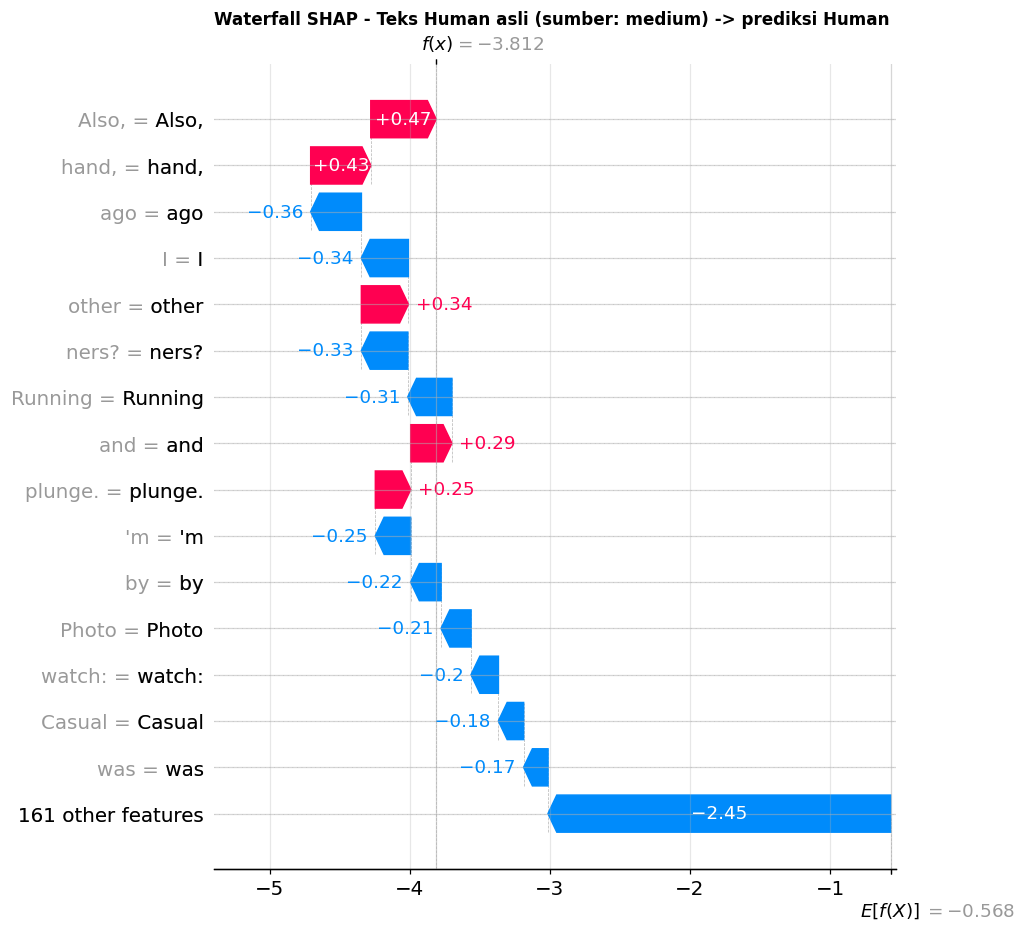


=== Contoh AI (sumber: Rotten_Tomato) | prediksi: AI | P(AI)=0.9796 ===


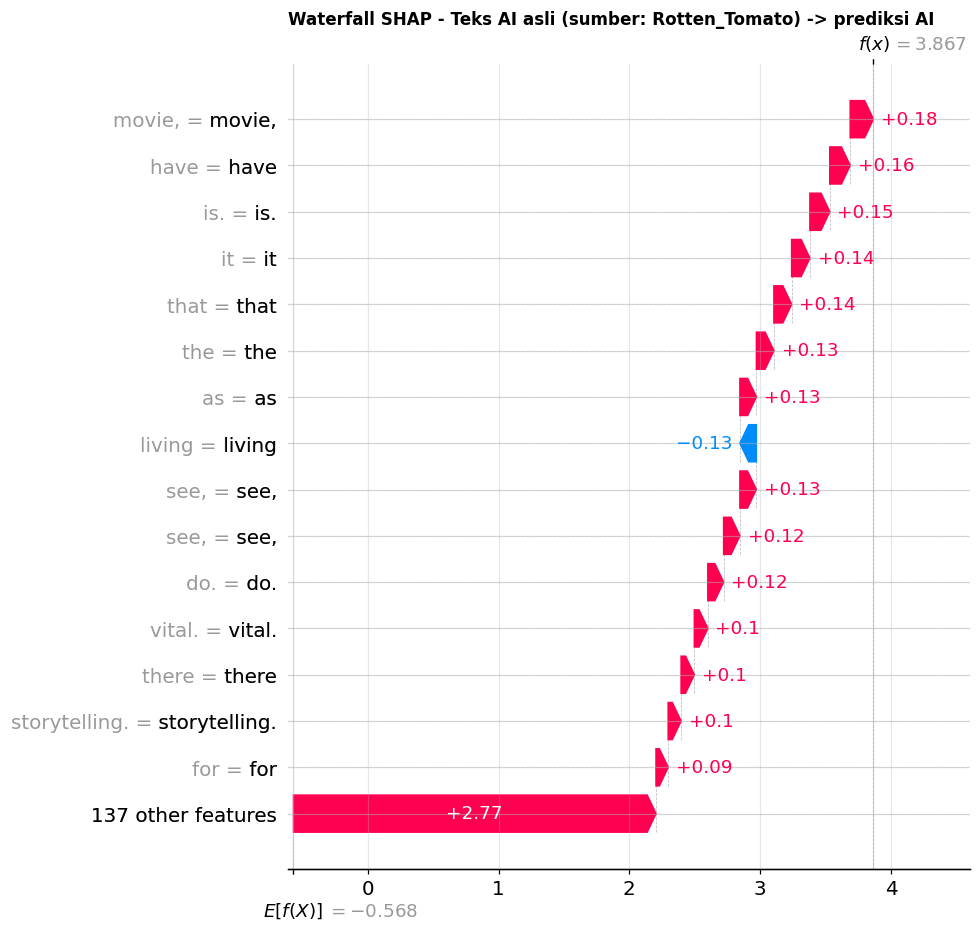

In [23]:
def pick_example(label, seed=SEED):
    d = df_test20[df_test20['label'] == label].sample(60, random_state=seed)
    p = prob_ai(d['clean_text'].tolist())
    ok = d[(p >= THRESHOLD).astype(int) == label].copy(); ok['p'] = p[(p >= THRESHOLD).astype(int) == label]
    ok['wc'] = ok['clean_text'].str.split().str.len()
    ok = ok[(ok['wc'] >= 80) & (ok['wc'] <= 250)]
    return (ok.iloc[(ok['p'] - label).abs().argsort()[:1]] if len(ok) else d.head(1)).iloc[0]

ex = {lab: pick_example(lab) for lab in (0, 1)}
EX_RES = {}
for lab, name in [(0, 'Human'), (1, 'AI')]:
    row = ex[lab]; r = explain_text(row['clean_text']); EX_RES[lab] = r
    print(f"\n=== Contoh {name} (sumber: {row['source']}) | prediksi: {r['pred']} | P(AI)={r['prob_model']:.4f} ===")
    shap.plots.waterfall(to_explanation(r), max_display=16, show=False)
    plt.title(f'Waterfall SHAP - Teks {name} asli (sumber: {row["source"]}) -> prediksi {r["pred"]}', fontsize=11, loc='left')
    plt.savefig(f'{RES_DIR}/waterfall_{name.lower()}.png', dpi=300, bbox_inches='tight'); plt.show()
    render_panel(r, title=f'Analysis Result - contoh {name} asli')

### Variasi: Kontribusi Kata Terbesar (bar lokal) dan Kurva Kumulatif
Bar horizontal kata paling berpengaruh (dengan arah) dan **kurva kumulatif SHAP** sepanjang teks (menunjukkan di bagian mana keputusan terbentuk).

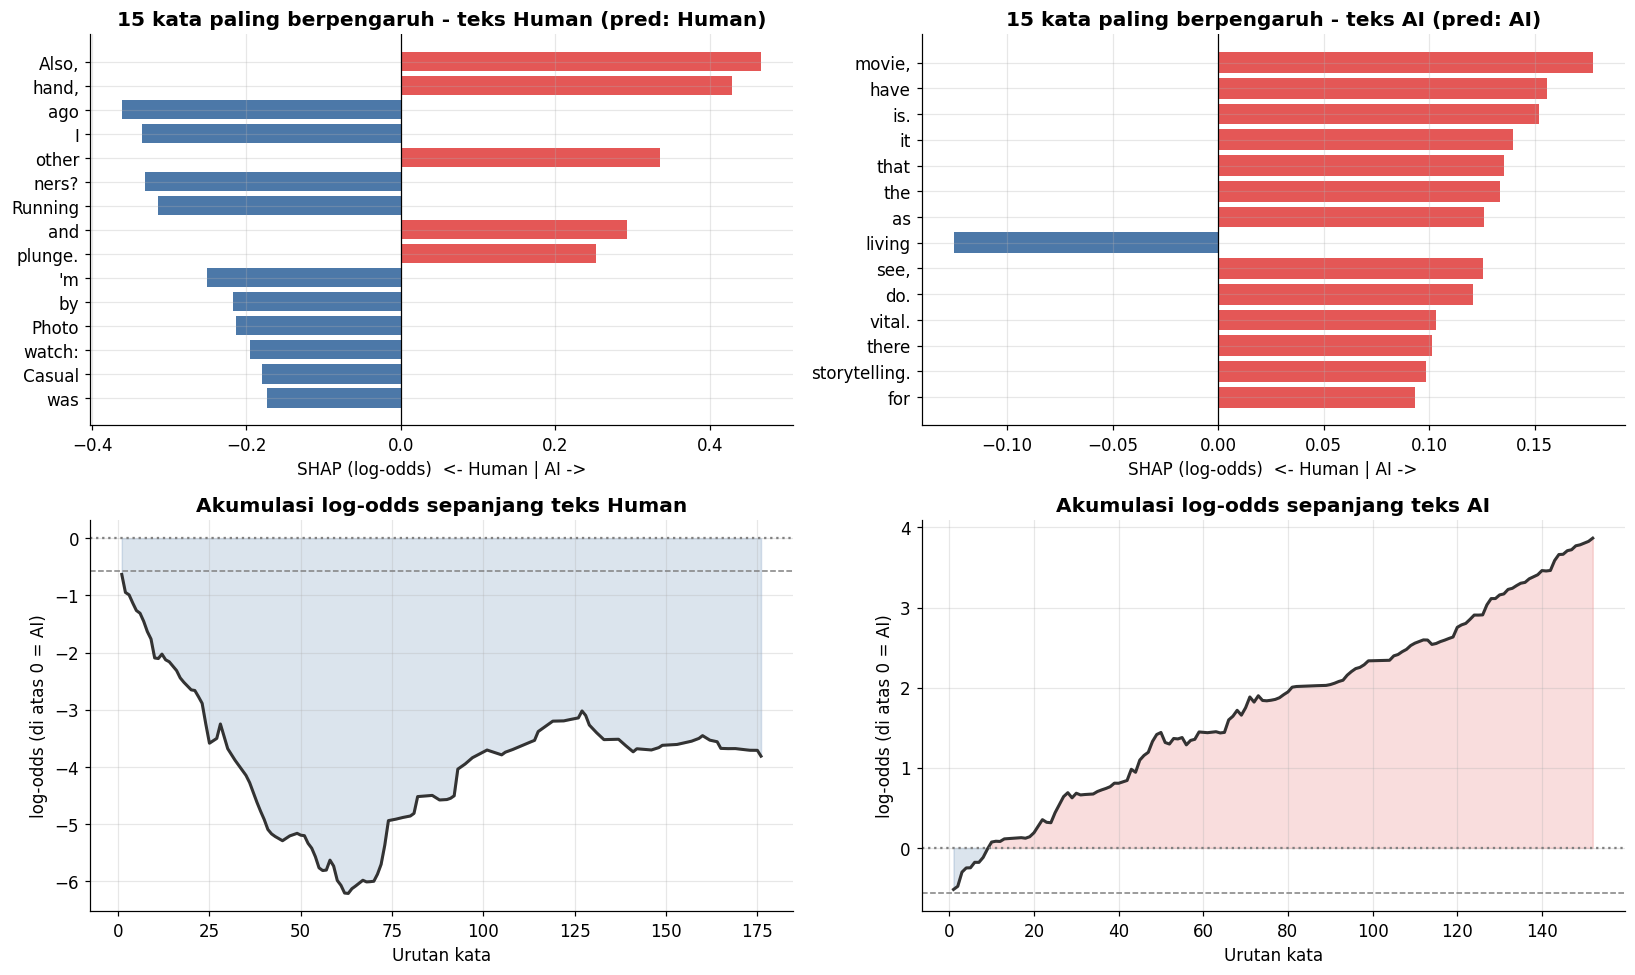

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for j, (lab, name) in enumerate([(0, 'Human'), (1, 'AI')]):
    r = EX_RES[lab]; v = r['values']; w = np.array(r['words'])
    top = np.argsort(-np.abs(v))[:15][::-1]
    ax = axes[0, j]; ax.barh([f'{w[i]}' for i in top], v[top], color=[C_AI if v[i] > 0 else C_HUMAN for i in top])
    ax.axvline(0, color='k', lw=0.8); ax.set_title(f'15 kata paling berpengaruh - teks {name} (pred: {r["pred"]})'); ax.set_xlabel('SHAP (log-odds)  <- Human | AI ->')
    ax = axes[1, j]; cum = r['base'] + np.cumsum(v)
    ax.plot(np.arange(1, len(v) + 1), cum, color='#333', lw=2); ax.axhline(0, color='gray', ls=':'); ax.axhline(r['base'], color='gray', ls='--', lw=1)
    ax.fill_between(np.arange(1, len(v) + 1), 0, cum, where=cum > 0, color=C_AI, alpha=0.2); ax.fill_between(np.arange(1, len(v) + 1), 0, cum, where=cum <= 0, color=C_HUMAN, alpha=0.2)
    ax.set_title(f'Akumulasi log-odds sepanjang teks {name}'); ax.set_xlabel('Urutan kata'); ax.set_ylabel('log-odds (di atas 0 = AI)')
plt.tight_layout(); plt.savefig(f'{RES_DIR}/shap_lokal_bar_kumulatif.png', dpi=300, bbox_inches='tight'); plt.show()

## STEP 7 - SHAP pada Sampel Data Uji (Seimbang per Label x Sumber)
Hasil tiap teks disimpan ke `shap_samples.pkl` (aman jika sesi putus: sel dilanjutkan dari yang sudah selesai). Estimasi waktu: sekitar 20-40 detik per teks di T4 dengan 1 model.

In [25]:
PKL = f'{RES_DIR}/shap_samples.pkl'
samp = (df_test20.groupby(['label', 'source'], group_keys=False)
        .apply(lambda g: g.sample(min(N_PER_SOURCE, len(g)), random_state=SEED)).reset_index(drop=True))
print('Jumlah teks yang dijelaskan:', len(samp)); print(pd.crosstab(samp['label'], samp['source']))

# --- TAMBAHAN: Paksa hapus data lama agar dihitung ulang dengan fungsi baru ---
if os.path.exists(PKL):
    os.remove(PKL)
    print('File lama dihapus. Memulai hitung ulang dari awal...')
store = {}

from tqdm.auto import tqdm
for i, row in tqdm(list(samp.iterrows()), desc='SHAP'):
    key = int(row['orig_id']) if 'orig_id' in row else i
    # if key in store: continue  <-- Ini dihapus agar pasti dihitung ulang semua
    r = explain_text(row['clean_text']); r.update(label=int(row['label']), source=row['source'], orig_id=key)
    store[key] = r
    pickle.dump(store, open(PKL, 'wb'))
print('Selesai:', len(store), 'teks tersimpan di', PKL)

Jumlah teks yang dijelaskan: 24
source  Rotten_Tomato  WMT-16  medium  wikipedia
label                                           
0                   0       0       6          6
1                   6       6       0          0
File lama dihapus. Memulai hitung ulang dari awal...


SHAP:   0%|          | 0/24 [00:00<?, ?it/s]

Selesai: 24 teks tersimpan di /kaggle/working/results_shap/shap_samples.pkl


## STEP 8 - Tabel Level-Kata dan Cek Aditivitas SHAP

In [26]:
rows = []
for key, r in store.items():
    for w, v in zip(r['words'], r['values']):
        rows.append({'id': key, 'label': r['label'], 'source': r['source'], 'pred': r['pred'], 'word': w, 'wl': w.lower(),
                     'shap': v, 'abs': abs(v), 'cat': category(w)})
W = pd.DataFrame(rows)
W.to_csv(f'{RES_DIR}/shap_word_level.csv', index=False)

chk = pd.DataFrame([{'id': k, 'label': r['label'], 'source': r['source'], 'P(AI) model': r['prob_model'], 'P(AI) base+sum(SHAP)': r['prob'],
                     'selisih': abs(r['prob'] - r['prob_model']), 'prediksi': r['pred'], 'benar': (r['pred'] == 'AI') == bool(r['label'])}
                    for k, r in store.items()])
print('Rata-rata |selisih| P(AI) model vs base+sum(SHAP): %.4f (kecil = penjelasan setia pada model)' % chk['selisih'].mean())
print('Akurasi pada sampel SHAP: %.2f%%' % (chk['benar'].mean() * 100))
chk.to_csv(f'{RES_DIR}/shap_cek_aditivitas.csv', index=False); display(chk.head(8).round(4))
print('Total kata:', len(W), '| teks:', W['id'].nunique())

Rata-rata |selisih| P(AI) model vs base+sum(SHAP): 0.0003 (kecil = penjelasan setia pada model)
Akurasi pada sampel SHAP: 95.83%


,id,label,source,P(AI) model,P(AI) base+sum(SHAP),selisih,prediksi,benar
0,184262,0,medium,0.0209,0.0218,0.0009,Human,True
1,89975,0,medium,0.0206,0.0212,0.0006,Human,True
2,40324,0,medium,0.0216,0.0218,0.0002,Human,True
3,66580,0,medium,0.0208,0.0202,0.0005,Human,True
4,146323,0,medium,0.0211,0.0222,0.0011,Human,True
5,94039,0,medium,0.9792,0.9796,0.0004,AI,False
6,202000,0,wikipedia,0.0212,0.0214,0.0002,Human,True
7,200951,0,wikipedia,0.0210,0.0213,0.0003,Human,True


Total kata: 6901 | teks: 24


## STEP 9 - Interpretasi Global: Fitur Apa yang Paling Berpengaruh?
(Menjawab rumusan masalah 3.) Disajikan: (a) kata paling berpengaruh, (b) kata pendorong AI vs Human, (c) kategori linguistik, (d) perbandingan per sumber.

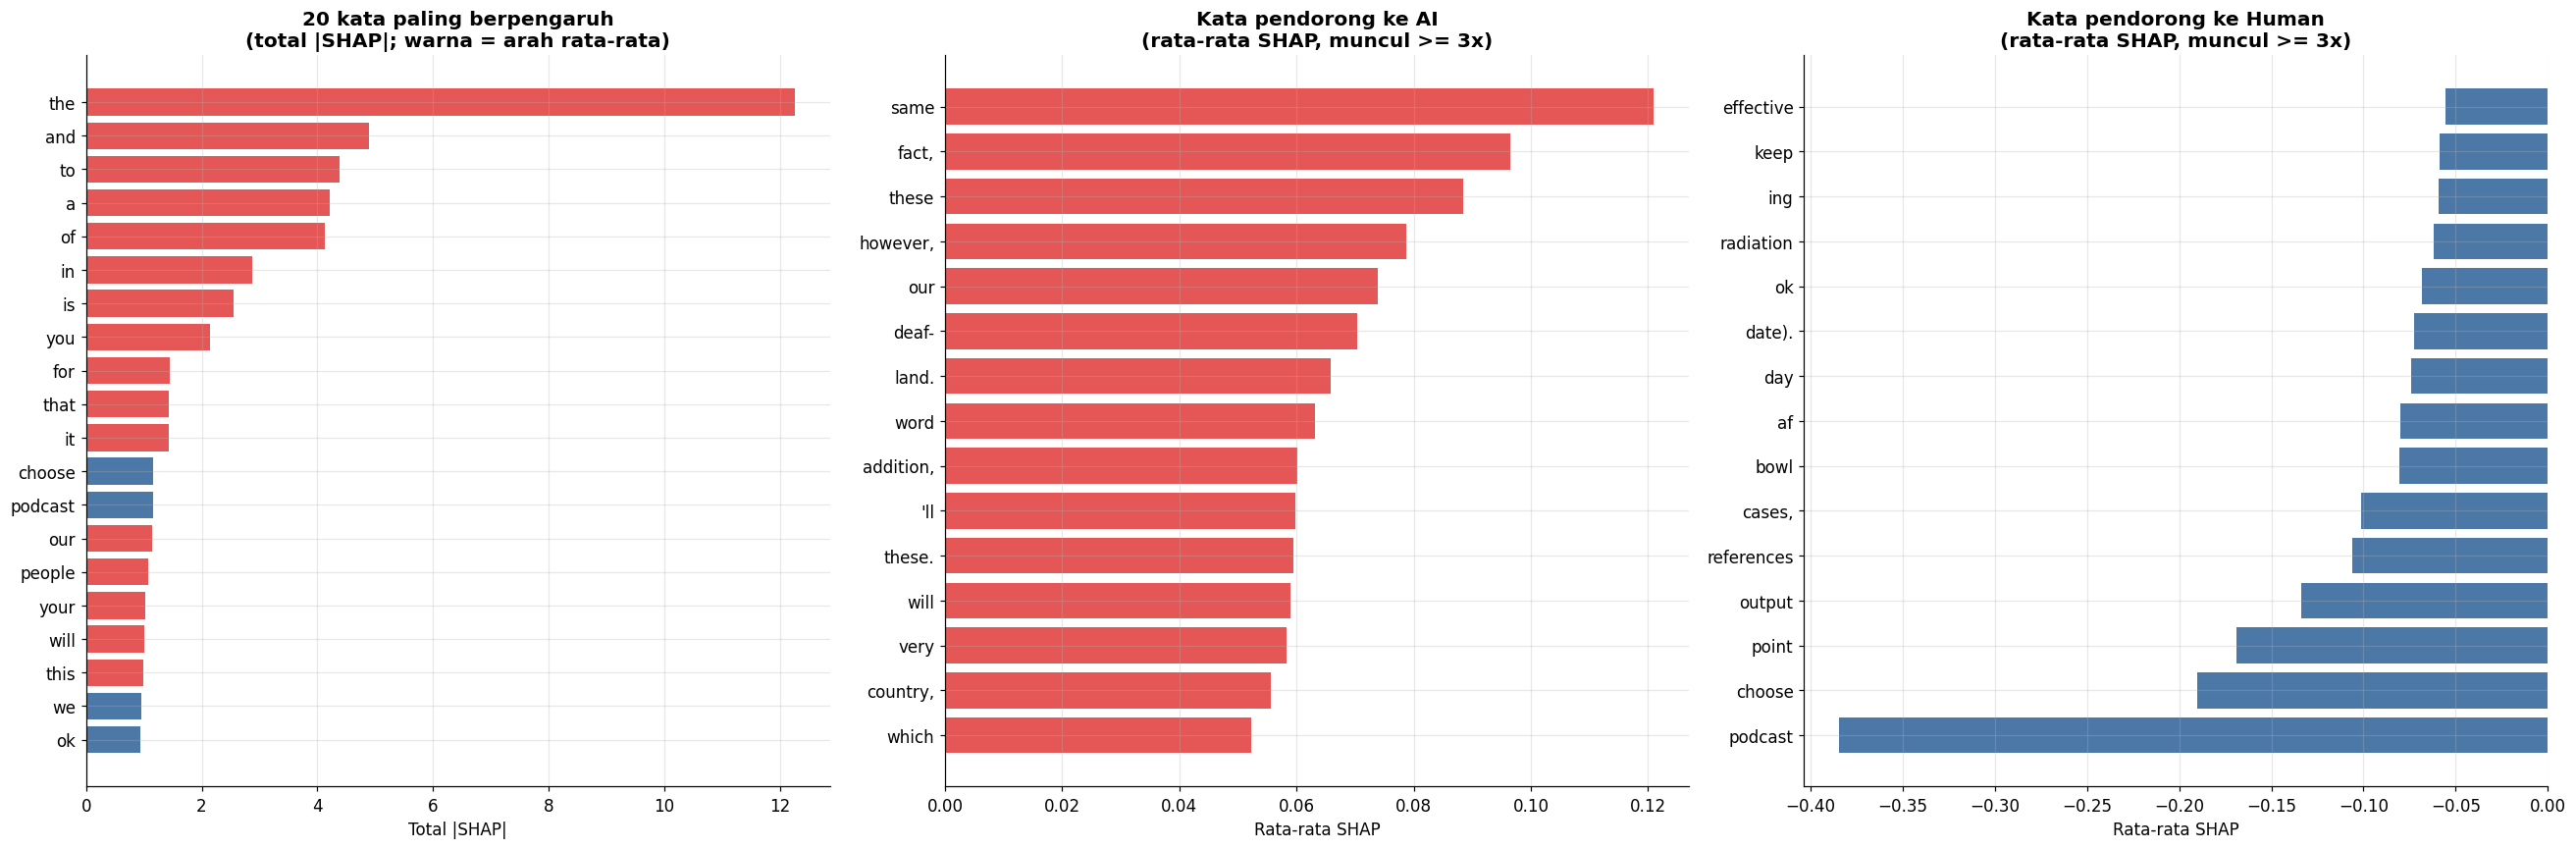

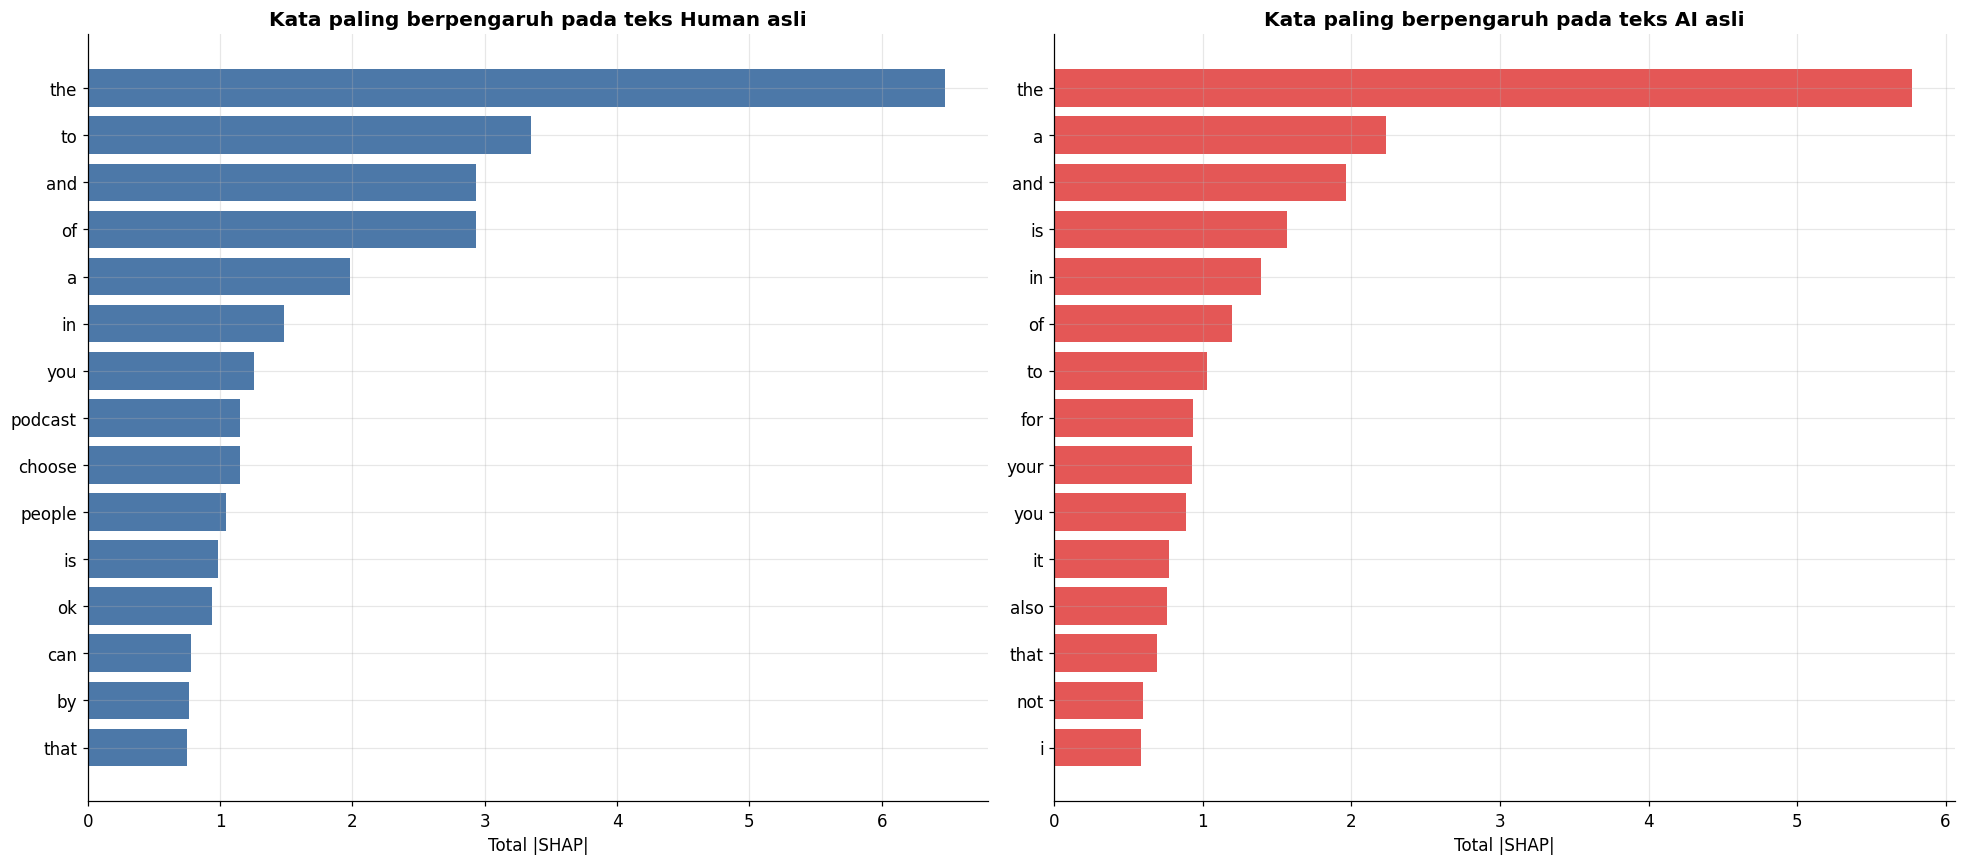

In [27]:
# (a)+(b) Kata paling berpengaruh -------------------------------------------------------------
MIN_CNT = 3
wordcat = W[~W['cat'].eq('Tanda baca')]
g = wordcat.groupby('wl').agg(n=('shap', 'size'), mean_shap=('shap', 'mean'), mean_abs=('abs', 'mean'), total_abs=('abs', 'sum')).reset_index()
g = g[g['n'] >= MIN_CNT]
fig, axes = plt.subplots(1, 3, figsize=(24, 8))
t = g.sort_values('total_abs', ascending=False).head(20).iloc[::-1]
axes[0].barh(t['wl'], t['total_abs'], color=[C_AI if m > 0 else C_HUMAN for m in t['mean_shap']])
axes[0].set_title('20 kata paling berpengaruh\n(total |SHAP|; warna = arah rata-rata)'); axes[0].set_xlabel('Total |SHAP|')
t = g.sort_values('mean_shap', ascending=False).head(15).iloc[::-1]
axes[1].barh(t['wl'], t['mean_shap'], color=C_AI); axes[1].set_title(f'Kata pendorong ke AI\n(rata-rata SHAP, muncul >= {MIN_CNT}x)'); axes[1].set_xlabel('Rata-rata SHAP')
t = g.sort_values('mean_shap').head(15)
axes[2].barh(t['wl'], t['mean_shap'], color=C_HUMAN); axes[2].set_title(f'Kata pendorong ke Human\n(rata-rata SHAP, muncul >= {MIN_CNT}x)'); axes[2].set_xlabel('Rata-rata SHAP')
plt.tight_layout(); plt.savefig(f'{RES_DIR}/shap_global_kata.png', dpi=300, bbox_inches='tight'); plt.show()
g.sort_values('total_abs', ascending=False).to_csv(f'{RES_DIR}/shap_global_kata.csv', index=False)

# kata paling berpengaruh per kelas asli
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, (lab, name, col) in zip(axes, [(0, 'Human', C_HUMAN), (1, 'AI', C_AI)]):
    s = W[(W['label'] == lab) & (~W['cat'].eq('Tanda baca'))].groupby('wl').agg(n=('abs', 'size'), tot=('abs', 'sum')).query('n >= 2').sort_values('tot', ascending=False).head(15).iloc[::-1]
    ax.barh(s.index, s['tot'], color=col); ax.set_title(f'Kata paling berpengaruh pada teks {name} asli'); ax.set_xlabel('Total |SHAP|')
plt.tight_layout(); plt.savefig(f'{RES_DIR}/shap_kata_per_kelas.png', dpi=300, bbox_inches='tight'); plt.show()

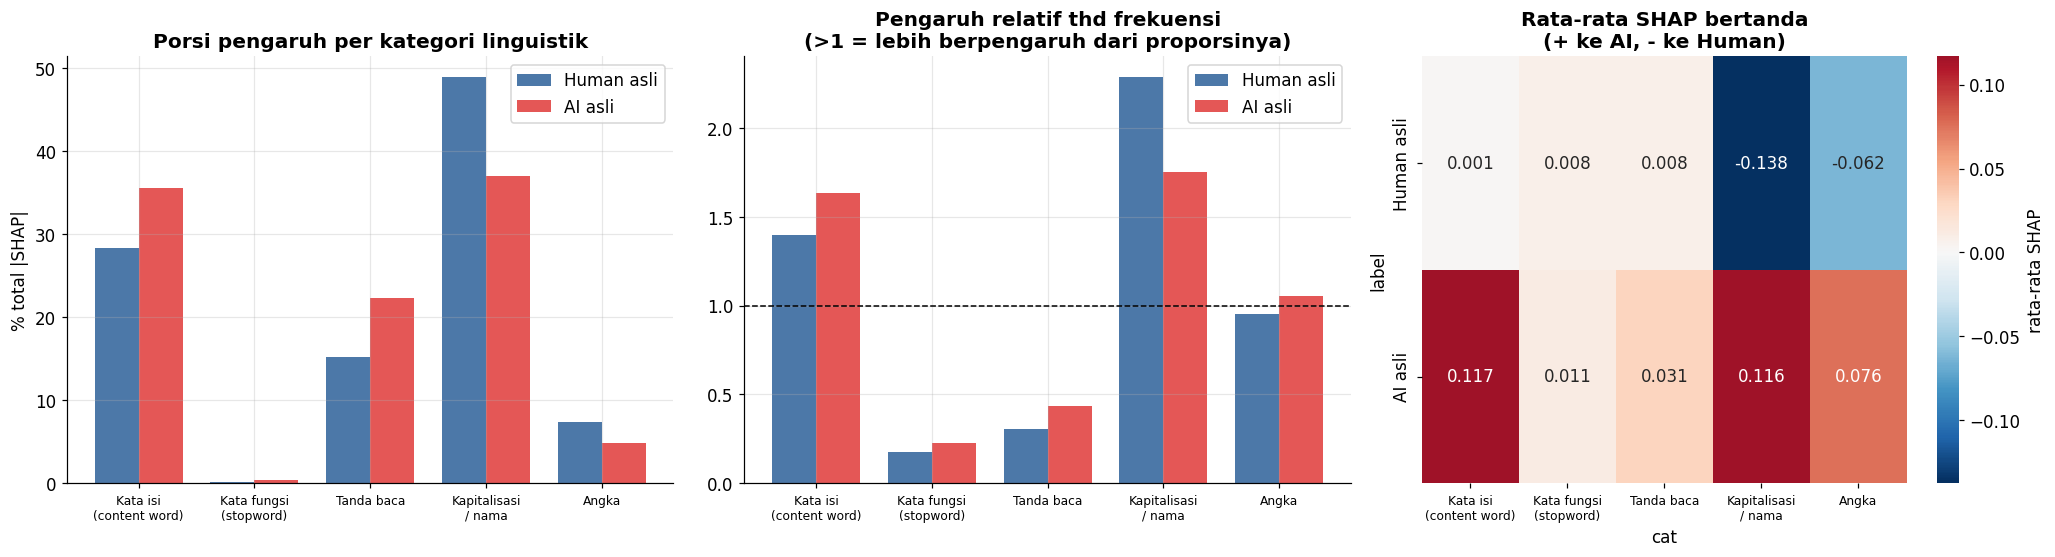

cat    Kata isi (content word)  Kata fungsi (stopword)  Tanda baca  \
label                                                                
0                        28.30                    0.15       15.20   
1                        35.54                    0.36       22.28   

cat    Kapitalisasi / nama  Angka  
label                              
0                    48.96   7.39  
1                    37.01   4.81  


In [15]:
# (c) Kategori linguistik ---------------------------------------------------------------------
CATS = ['Kata isi (content word)', 'Kata fungsi (stopword)', 'Tanda baca', 'Kapitalisasi / nama', 'Angka']
share = W.groupby(['label', 'cat'])['abs'].sum().unstack().reindex(columns=CATS).fillna(0)
share_pct = share.div(share.sum(axis=1), axis=0) * 100
cnt_pct = W.groupby(['label', 'cat']).size().unstack().reindex(columns=CATS).fillna(0)
cnt_pct = cnt_pct.div(cnt_pct.sum(axis=1), axis=0) * 100
signed = W.groupby(['label', 'cat'])['shap'].mean().unstack().reindex(columns=CATS)

fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
x = np.arange(len(CATS)); w = 0.38
for j, (lab, name, col) in enumerate([(0, 'Human asli', C_HUMAN), (1, 'AI asli', C_AI)]):
    axes[0].bar(x + (j - 0.5) * w, share_pct.loc[lab], w, color=col, label=name)
axes[0].set_xticks(x); axes[0].set_xticklabels([c.replace(' (', '\n(').replace(' / ', '\n/ ') for c in CATS], fontsize=8)
axes[0].set_ylabel('% total |SHAP|'); axes[0].set_title('Porsi pengaruh per kategori linguistik'); axes[0].legend()
for j, (lab, name, col) in enumerate([(0, 'Human asli', C_HUMAN), (1, 'AI asli', C_AI)]):
    axes[1].bar(x + (j - 0.5) * w, share_pct.loc[lab] / cnt_pct.loc[lab], w, color=col, label=name)
axes[1].axhline(1, color='k', ls='--', lw=1); axes[1].set_xticks(x); axes[1].set_xticklabels([c.replace(' (', '\n(').replace(' / ', '\n/ ') for c in CATS], fontsize=8)
axes[1].set_title('Pengaruh relatif thd frekuensi\n(>1 = lebih berpengaruh dari proporsinya)'); axes[1].legend()
import seaborn as sns
sns.heatmap(signed.rename(index={0: 'Human asli', 1: 'AI asli'}), annot=True, fmt='.3f', cmap='RdBu_r', center=0, ax=axes[2], cbar_kws={'label': 'rata-rata SHAP'})
axes[2].set_xticklabels([c.replace(' (', '\n(').replace(' / ', '\n/ ') for c in CATS], fontsize=8, rotation=0); axes[2].set_title('Rata-rata SHAP bertanda\n(+ ke AI, - ke Human)'); axes[2].grid(False)
plt.tight_layout(); plt.savefig(f'{RES_DIR}/shap_kategori_linguistik.png', dpi=300, bbox_inches='tight'); plt.show()
print(share_pct.round(2)); share_pct.to_csv(f'{RES_DIR}/shap_kategori_linguistik.csv')

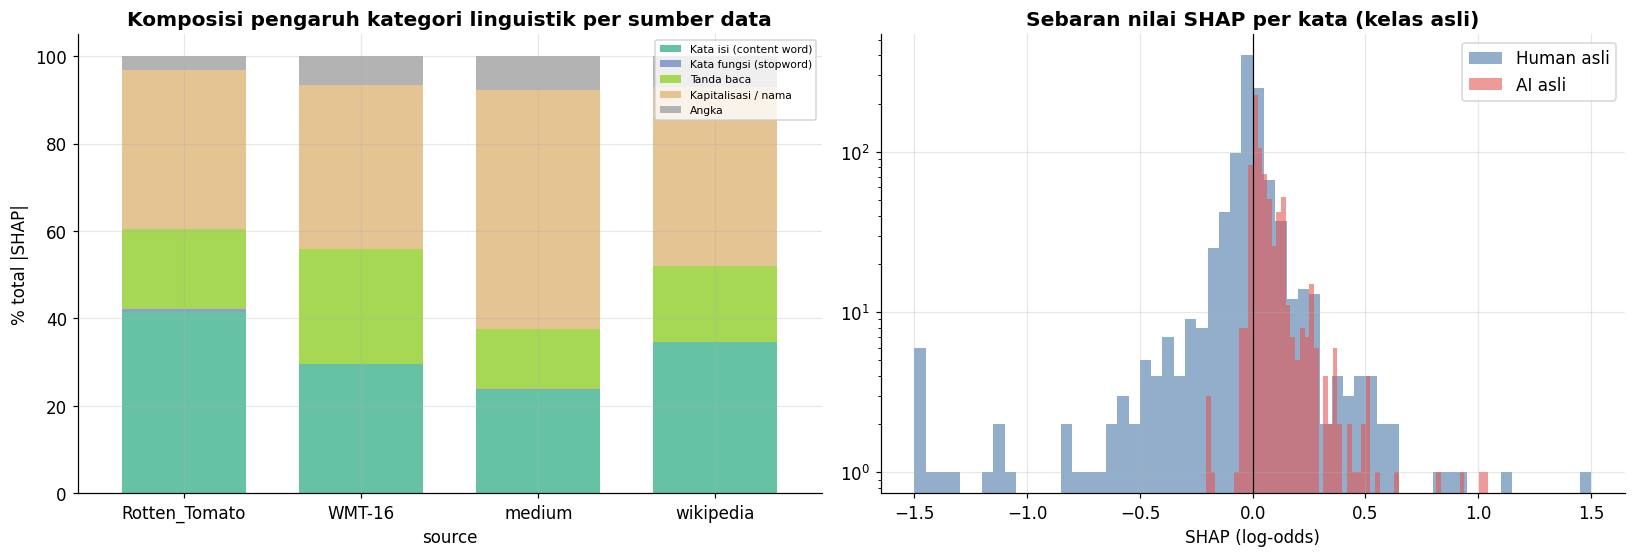

Konsentrasi pengaruh (% total |SHAP| yang dipegang kata teratas):
            top5_share  top10pct_share
label                                 
Human asli        44.0            49.8
AI asli           37.2            33.4


In [16]:
# (d) Per sumber + sebaran SHAP -----------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
ps = W.groupby(['source', 'cat'])['abs'].sum().unstack().reindex(columns=CATS).fillna(0)
(ps.div(ps.sum(axis=1), axis=0) * 100).plot(kind='bar', stacked=True, ax=axes[0], colormap='Set2', rot=0, width=0.7)
axes[0].set_ylabel('% total |SHAP|'); axes[0].set_title('Komposisi pengaruh kategori linguistik per sumber data'); axes[0].legend(fontsize=7, loc='upper right')
wl_ = W.groupby('id').agg(label=('label', 'first'), source=('source', 'first'), tot=('shap', 'sum'), mx=('abs', 'max'))
for lab, name, col in [(0, 'Human asli', C_HUMAN), (1, 'AI asli', C_AI)]:
    axes[1].hist(W[W['label'] == lab]['shap'].clip(-1.5, 1.5), bins=60, alpha=0.6, color=col, label=name)
axes[1].set_yscale('log'); axes[1].axvline(0, color='k', lw=0.8); axes[1].set_title('Sebaran nilai SHAP per kata (kelas asli)'); axes[1].set_xlabel('SHAP (log-odds)'); axes[1].legend()
plt.tight_layout(); plt.savefig(f'{RES_DIR}/shap_per_sumber_sebaran.png', dpi=300, bbox_inches='tight'); plt.show()

# Ringkasan 1 gambar: dominasi beberapa kata -----------------------------------------------------
conc = []
for k, r in store.items():
    a = np.sort(np.abs(r['values']))[::-1]; conc.append({'label': r['label'], 'top5_share': a[:5].sum() / a.sum() * 100, 'top10pct_share': a[:max(1, len(a)//10)].sum() / a.sum() * 100})
conc = pd.DataFrame(conc).groupby('label').mean().rename(index={0: 'Human asli', 1: 'AI asli'})
print('Konsentrasi pengaruh (% total |SHAP| yang dipegang kata teratas):'); print(conc.round(1))

## STEP 9B - Galeri Teks Ter-highlight (untuk lampiran skripsi)
Satu teks per kombinasi label x sumber, dengan gaya prototipe (Human biru, AI merah).

In [17]:
seen = set()
for key, r in store.items():
    k = (r['label'], r['source'])
    if k in seen: continue
    seen.add(k)
    render_panel(r, title=f"Analysis Result - asli: {'AI' if r['label'] else 'Human'} | sumber: {r['source']}")

## STEP 10 - Ringkasan Performa Model & Hasil untuk Laporan
Membaca file hasil RoBERTa yang sudah tersimpan (tanpa training ulang) agar RM 3 (performa + fitur dominan) terlihat dalam satu notebook.

In [18]:
res_csv = find_first('/kaggle/**/ringkasan_hasil.csv') or find_first('/kaggle/**/ringkasan_final.csv')
if res_csv:
    print('Sumber:', res_csv); display(pd.read_csv(res_csv))
else:
    print('ringkasan_hasil.csv tidak ditemukan (opsional).')

top_ai  = g.sort_values('mean_shap', ascending=False).head(8)['wl'].tolist()
top_hum = g.sort_values('mean_shap').head(8)['wl'].tolist()
dom = share_pct.idxmax(axis=1).to_dict()
print('\n' + '=' * 80 + '\nINTERPRETASI OTOMATIS (dari hasil SHAP)\n' + '=' * 80)
print(f'1. Kata yang paling mendorong prediksi ke AI : {", ".join(top_ai)}')
print(f'2. Kata yang paling mendorong prediksi ke Human: {", ".join(top_hum)}')
print(f'3. Kategori linguistik dengan porsi |SHAP| terbesar -> Human asli: {dom.get(0)} | AI asli: {dom.get(1)}')
print(f'4. Kesetiaan penjelasan: rata-rata |P(AI) model - P(AI) dari base+SHAP| = {chk["selisih"].mean():.4f}')
print('5. Catatan: SHAP menjelaskan apa yang dipelajari MODEL, bukan kebenaran kausal. Dataset ini memiliki label yang terkait sumber')
print('   (Human = Medium+Wikipedia, AI = Rotten_Tomato+WMT-16), sehingga kata/gaya khas sumber dapat tampil sebagai fitur dominan;')
print('   bahas bersama hasil uji lintas-sumber pada bab pembahasan.')
print('=' * 80)

Sumber: /kaggle/input/notebooks/qiransalsabillahmuz/bismillah-acc2/results/ringkasan_hasil.csv


,Evaluasi,n,Akurasi %,Macro-F1,Prec Human,Rec Human,Prec AI,Rec AI,AUC
0,CV 5-fold OOF (data 80%),7822,99.00,0.9900,0.9950,0.9847,0.9853,0.9952,0.9983
1,Test 20% - Ensemble 5 model,1956,99.08,0.9908,0.9989,0.9824,0.9831,0.9990,0.9999
2,Lintas-sumber 1: medium+RT -> wiki+WMT,3412,50.59,0.4173,0.4769,0.9935,0.9519,0.1057,0.8525
3,Lintas-sumber 2: wiki+WMT -> medium+RT,4410,49.41,0.3623,1.0000,0.0375,0.4839,1.0000,0.5532



INTERPRETASI OTOMATIS (dari hasil SHAP)
1. Kata yang paling mendorong prediksi ke AI : thefactthatcanadianswouldbeabletoaffordtospendtoomuchinasmallway, withfederalgovernmentsandindustryannouncingstrongsupportfortheconservationanddevelopmentofthecountry, anditistheareathatthesunis, expertsaroundtheworldarelookingforwardtoseeingacountrythathasaunique, canadaisactuallymoreexpensivetospendonland, uniqueconservationhistory, infact, inaddition
2. Kata yang paling mendorong prediksi ke Human: disambiguation, canada'saverageincomeisjustshyof, williamii, however, approximatedate, 0, 10, mentalhealth
3. Kategori linguistik dengan porsi |SHAP| terbesar -> Human asli: Kapitalisasi / nama | AI asli: Kapitalisasi / nama
4. Kesetiaan penjelasan: rata-rata |P(AI) model - P(AI) dari base+SHAP| = 0.0003
5. Catatan: SHAP menjelaskan apa yang dipelajari MODEL, bukan kebenaran kausal. Dataset ini memiliki label yang terkait sumber
   (Human = Medium+Wikipedia, AI = Rotten_Tomato+WMT-16), sehingga kata/ga

## STEP 11 - Uji Teks Sendiri + Penjelasan SHAP (seperti prototipe)
Tempel teks berbahasa Inggris (minimal sekitar 50 kata), jalankan sel, lalu lihat klasifikasi, waterfall, dan highlight.

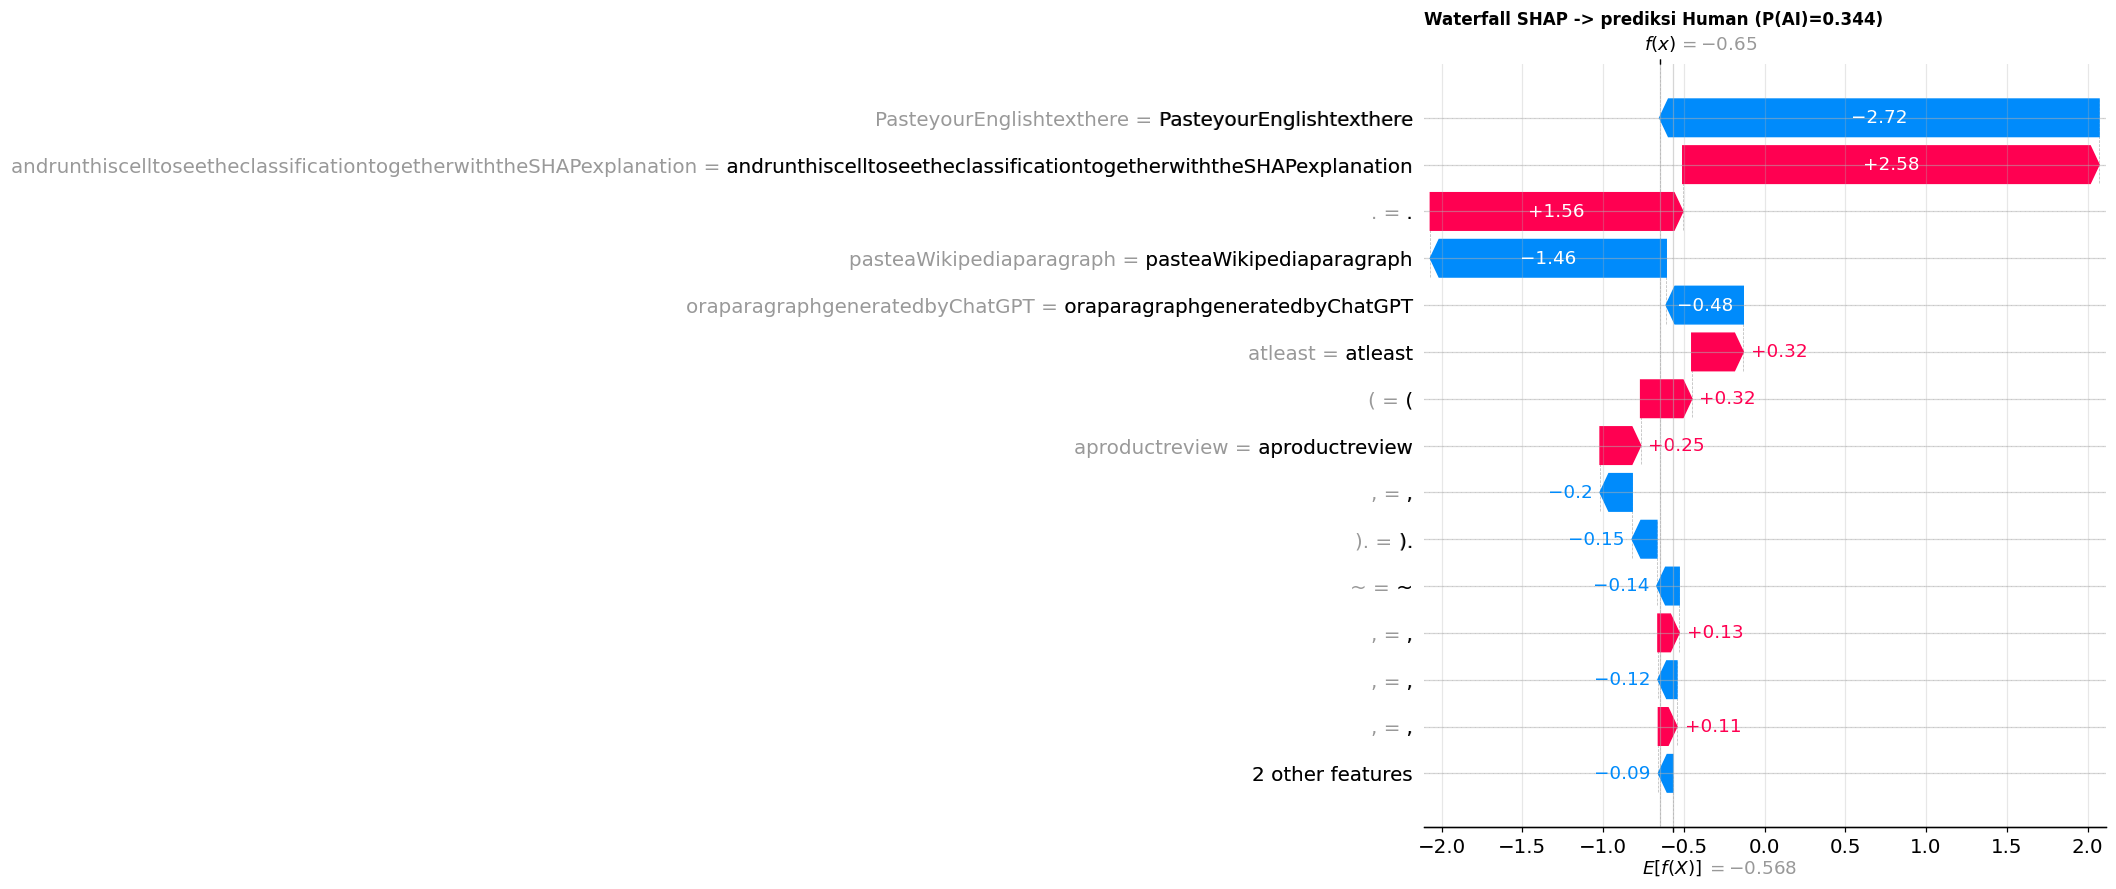

In [19]:
INPUT_TEXT = '''Paste your English text here (at least ~50 words). For example, paste a Wikipedia paragraph, a product review, or a paragraph generated by ChatGPT, and run this cell to see the classification together with the SHAP explanation.'''

def analyze(text, waterfall=True):
    r = explain_text(text)
    render_panel(r)
    if waterfall:
        shap.plots.waterfall(to_explanation(r), max_display=15, show=False)
        plt.title(f'Waterfall SHAP -> prediksi {r["pred"]} (P(AI)={r["prob_model"]:.3f})', fontsize=11, loc='left')
        plt.savefig(f'{RES_DIR}/waterfall_input_sendiri.png', dpi=300, bbox_inches='tight'); plt.show()
    return r
_ = analyze(INPUT_TEXT)

## STEP 12 - Paket Hasil
Semua gambar dan tabel SHAP disimpan di `results_shap/` dan dikemas dalam satu zip (otomatis masuk Output Kaggle saat *Save Version*).

In [20]:
import shutil
z = shutil.make_archive(f'{WORKING_DIR}/hasil_shap', 'zip', RES_DIR)
print('Paket:', z, f'({os.path.getsize(z)/1e6:.1f} MB)'); print(sorted(os.listdir(RES_DIR)))

Paket: /kaggle/working/hasil_shap.zip (3.4 MB)
['shap_cek_aditivitas.csv', 'shap_global_kata.csv', 'shap_global_kata.png', 'shap_kata_per_kelas.png', 'shap_kategori_linguistik.csv', 'shap_kategori_linguistik.png', 'shap_lokal_bar_kumulatif.png', 'shap_per_sumber_sebaran.png', 'shap_samples.pkl', 'shap_word_level.csv', 'waterfall_ai.png', 'waterfall_human.png', 'waterfall_input_sendiri.png']


## Catatan untuk Dilaporkan
- **Metode:** Partition SHAP dengan masker teks tokenizer RoBERTa; keluaran dijelaskan dalam log-odds P(AI) sehingga *base value* + jumlah SHAP = keluaran model.
- **Model yang dijelaskan:** `SHAP_FOLDS` (default fold 1). Isi `[1,2,3,4,5]` untuk menjelaskan ensemble yang sama dengan pengujian STEP 11 di notebook RoBERTa.
- **Sampel:** seimbang per label x sumber dari data uji 20% (tidak dipakai untuk training/tuning).
- **Interpretasi:** SHAP menunjukkan fitur yang memengaruhi keputusan model (bukan bukti kausal tentang penulis teks). Bahas bersama keterbatasan dataset (label terkait sumber).
- **Gambar utama laporan:** `waterfall_human.png`, `waterfall_ai.png`, `shap_global_kata.png`, `shap_kategori_linguistik.png`, serta panel highlight (screenshot).